# RAG Assignment: Baseline Bi-Encoder Retrieval vs. Cross-Encoder Re-Ranking

**Document:** *CATAN Game Rules & Almanac* (16-page board-game rulebook, `data/catan_rules.pdf`).
It is a good stress-test corpus: the Almanac is organised as alphabetical entries, so a rule, its exceptions and its
restrictions often live in *different* chunks.

| Component | Choice |
|---|---|
| Bi-Encoder (stage 1) | `sentence-transformers/all-MiniLM-L6-v2` + FAISS `IndexFlatIP` (normalised vectors, so inner product = cosine) |
| Cross-Encoder (stage 2) | `cross-encoder/ms-marco-MiniLM-L6-v2` |
| LLM | `Qwen/Qwen2.5-3B-Instruct` (local, CPU, greedy decoding, so runs are reproducible) |

**Pipeline 1:** top-10 by cosine, take top-3 to LLM -> Answer 1.
**Pipeline 2:** the same top-10, score every (query, chunk) pair with the Cross-Encoder, re-sort, take top-3 to the *identical* prompt -> Answer 2.

In [1]:
import re, json, time, random, textwrap
import numpy as np, pandas as pd, torch, faiss, pymupdf
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))

PDF_PATH   = "data/catan_rules.pdf"
BI_MODEL   = "sentence-transformers/all-MiniLM-L6-v2"
CE_MODEL   = "cross-encoder/ms-marco-MiniLM-L6-v2"
LLM_MODEL  = "Qwen/Qwen2.5-3B-Instruct"
TOP_K, TOP_N = 10, 3      # retrieve 10, give 3 to the LLM

/home/karthik/Desktop/SEM III/LMA/RAG_PROJECT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the PDF and chunk it
We read the text block by block (PyMuPDF keeps the multi-column reading order correctly), strip page furniture (copyright lines, dice-pip dots), and pack consecutive blocks from the same page into chunks of roughly 130 words. Both pipelines use exactly this chunk list.

In [2]:
def clean(t):
    t = re.sub(r'©\s*\d{4}\s*Catan GmbH', '', t)            # copyright footers
    t = re.sub(r'(?:\b\d{1,2}\b\s*)?[•\s]{3,}', ' ', t)       # number-token pips "8 •••••"
    return re.sub(r'\s+', ' ', t).strip()

def load_chunks(path, target_words=130):
    doc, blocks = pymupdf.open(path), []
    for pno, page in enumerate(doc, 1):
        if pno == 1:            # cover page, no rules
            continue
        for b in page.get_text('blocks'):
            if b[6] != 0:       # skip image blocks
                continue
            t = clean(b[4])
            if len(t.split()) >= 5:
                blocks.append((pno, t))
    chunks, cur, pg, n = [], [], None, 0
    for pno, t in blocks:
        w = len(t.split())
        if cur and (pno != pg or n + w > target_words):
            chunks.append({'page': pg, 'text': ' '.join(cur)}); cur, n = [], 0
        cur.append(t); pg = pno; n += w
    if cur:
        chunks.append({'page': pg, 'text': ' '.join(cur)})
    return chunks

chunks = load_chunks(PDF_PATH)
texts  = [c['text'] for c in chunks]
print(f"{len(chunks)} chunks, mean {np.mean([len(t.split()) for t in texts]):.0f} words")
print("\nExample chunk 56 (page %d):\n%s" % (chunks[56]['page'], textwrap.fill(texts[56], 110)))

82 chunks, mean 112 words

Example chunk 56 (page 11):
more than 7 resource cards (i.e., 8 or more) must choose and discard half of them. Return discards to the
supply stacks. If you hold an odd number of cards, round down (e.g., if you have 9 resource cards, you discard
4). Example: Alex rolls a “7.” He has only 6 cards in his hand. Larry has 8 cards and Will has 11. Larry must
discard 4 cards and Will 5 (rounding down). (2) Then you (the player who rolled the “7”) must move


## 2. Stage 1: dense index (Bi-Encoder + FAISS)

In [3]:
bi = SentenceTransformer(BI_MODEL)
doc_emb = bi.encode(texts, normalize_embeddings=True, convert_to_numpy=True).astype('float32')
index = faiss.IndexFlatIP(doc_emb.shape[1])     # inner product on unit vectors == cosine similarity
index.add(doc_emb)
print(index.ntotal, "vectors of dim", doc_emb.shape[1])

def baseline_retrieve(query, k=TOP_K):
    """Pipeline 1 retrieval: returns (chunk ids, cosine scores) of the top-k."""
    q = bi.encode([query], normalize_embeddings=True).astype('float32')
    scores, ids = index.search(q, k)
    return ids[0].tolist(), scores[0].tolist()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9074.00it/s]

82 vectors of dim 384


## 3. Stage 2: Cross-Encoder re-ranker

In [4]:
ce = CrossEncoder(CE_MODEL)

def rerank(query, cand_ids):
    """Pipeline 2 re-ranking: score each (query, chunk) pair jointly, sort descending."""
    scores = ce.predict([(query, texts[i]) for i in cand_ids])
    order = np.argsort(-scores)
    return [cand_ids[j] for j in order], [float(scores[j]) for j in order]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 8361.69it/s]

## 4. LLM and the (identical) prompt
Both pipelines call `generate_answer` with the same system prompt and the same layout; only the three context chunks differ. Greedy decoding (no sampling), so any difference between Answer 1 and Answer 2 comes only from the retrieved context.

In [5]:
tok = AutoTokenizer.from_pretrained(LLM_MODEL)
llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.bfloat16).eval()

SYSTEM = ("You are a rules assistant for the board game Catan. Answer the question using ONLY the context passages. "
          "If the passages do not contain the answer, say 'The context does not say.' Answer in at most 3 sentences.")

def generate_answer(query, chunk_ids):
    ctx = "\n\n".join(f"[Passage {n+1}] {texts[i]}" for n, i in enumerate(chunk_ids))
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {query}"}]
    enc = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors='pt', return_dict=True)
    with torch.no_grad():
        out = llm.generate(**enc, max_new_tokens=120, do_sample=False)
    return tok.decode(out[0][enc['input_ids'].shape[1]:], skip_special_tokens=True).strip()

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 434/434 [00:00<00:00, 8696.18it/s]

## 5. Test queries

Each query is tagged with the failure mode it probes. `gold` is a regex that identifies the chunk containing the clause that actually answers the question. It is **only used for evaluation** (to report ranks), never by the pipelines.
A sanity query that the baseline should get right is included as a control, and one query where *both* pipelines are expected to fail (the answer chunk is not in the baseline's top 10, so re-ranking cannot help).

In [6]:
QUERIES = [
 # (id, failure mode, query, regex for the chunk holding the deciding clause)
 ("Q1", "Exception / corner case",
  "If I buy a victory point card that gets me to 10 points, do I have to wait for my next turn?",
  r"Exception: If you buy a card"),
 ("Q2", "Exception / corner case",
  "After I play a progress card, can I play it again later?",
  r"removed from the game"),
 ("Q3", "Exception / corner case (partial)",
  "Do I get any resources if a robber-blocked number is rolled?",
  r"receive no resources from this hex"),
 ("Q4", "Negation / constraint",
  "Can I play two knight cards in the same turn?",
  r"only play 1 development card during your turn"),
 ("Q5", "Negation / constraint",
  "Can I build a sixth settlement if I already have five on the board?",
  r"all 5 of your settlements"),
 ("Q6", "Negation / constraint",
  "Can I place more than one road on the same path?",
  r"Only 1 road"),
 ("Q7", "Keyword trap / synonyms",
  "Which hex never produces anything for anybody?",
  r"only terrain hex that does not produce"),
 ("Q8", "Other: answer buried at rank 10",
  "Who gets starting resources and from which settlement?",
  r"second settlement"),
 ("Q9", "Limitation (answer outside top-10)",
  "Do roads count toward my score?",
  r"Roads provide victory points only"),
 ("Q10", "Control (easy query)",
  "Can a player win the game during an opponent's turn?",
  r"must wait until your next turn"),
]
def gold_ids(rx): return [i for i, t in enumerate(texts) if re.search(rx, t)]
for qid, mode, q, rx in QUERIES:
    print(qid, "gold chunk(s):", gold_ids(rx), "|", q)

Q1 gold chunk(s): [29] | If I buy a victory point card that gets me to 10 points, do I have to wait for my next turn?
Q2 gold chunk(s): [19] | After I play a progress card, can I play it again later?
Q3 gold chunk(s): [54] | Do I get any resources if a robber-blocked number is rolled?
Q4 gold chunk(s): [29] | Can I play two knight cards in the same turn?
Q5 gold chunk(s): [60] | Can I build a sixth settlement if I already have five on the board?
Q6 gold chunk(s): [13, 53] | Can I place more than one road on the same path?
Q7 gold chunk(s): [28] | Which hex never produces anything for anybody?
Q8 gold chunk(s): [62, 63] | Who gets starting resources and from which settlement?
Q9 gold chunk(s): [53] | Do roads count toward my score?
Q10 gold chunk(s): [32] | Can a player win the game during an opponent's turn?


## 6. Run both pipelines on every query
For each query we record the baseline ranking, the re-ranked order, the position of the gold chunk in each, and both LLM answers.

In [7]:
def rank_of(gold, ordered):
    r = [ordered.index(g) + 1 for g in gold if g in ordered]
    return min(r) if r else None          # None = not in the top-10

results = []
for qid, mode, q, rx in QUERIES:
    gold = gold_ids(rx)
    ids, cos = baseline_retrieve(q)                 # Pipeline 1 stage 1: top-10 by cosine
    rr_ids, ce_scores = rerank(q, ids)              # Pipeline 2: re-order the same 10
    ans1 = generate_answer(q, ids[:TOP_N])          # Answer 1: baseline top-3
    ans2 = generate_answer(q, rr_ids[:TOP_N])       # Answer 2: re-ranked top-3
    results.append(dict(qid=qid, mode=mode, query=q, gold=gold, base_ids=ids, cos=cos,
                        rr_ids=rr_ids, ce=ce_scores, base_rank=rank_of(gold, ids),
                        ce_rank=rank_of(gold, rr_ids), ans1=ans1, ans2=ans2))
    print(qid, "done")

Q1 done


Q2 done


Q3 done


Q4 done


Q5 done


Q6 done


Q7 done


Q8 done


Q9 done


Q10 done


### 6a. Rank-shift summary

In [8]:
rows = []
for r in results:
    rows.append({"Query": r["qid"], "Failure mode": r["mode"], "Gold chunk": r["gold"][0],
                 "Baseline rank": r["base_rank"] or ">10", "Re-ranked rank": r["ce_rank"] or ">10",
                 "In baseline top-3?": (r["base_rank"] or 99) <= 3,
                 "In re-ranked top-3?": (r["ce_rank"] or 99) <= 3})
rank_df = pd.DataFrame(rows)
rank_df.to_csv("results/rank_shift.csv", index=False)
rank_df

,Query,Failure mode,Gold chunk,Baseline rank,Re-ranked rank,In baseline top-3?,In re-ranked top-3?
0,Q1,Exception / corner case,29,7,3,False,True
1,Q2,Exception / corner case,19,10,2,False,True
2,Q3,Exception / corner case (partial),54,7,4,False,False
3,Q4,Negation / constraint,29,6,1,False,True
4,Q5,Negation / constraint,60,7,2,False,True
5,Q6,Negation / constraint,13,8,2,False,True
6,Q7,Keyword trap / synonyms,28,4,1,False,True
7,Q8,Other: answer buried at rank 10,62,10,1,False,True
8,Q9,Limitation (answer outside top-10),53,>10,>10,False,False
9,Q10,Control (easy query),32,1,1,True,True


### 6b. Per-query detail: top-3 of each pipeline and the two answers

In [9]:
def snip(i, n=170): return textwrap.shorten(texts[i], n, placeholder=" ...")
for r in results:
    print("="*110)
    print(f"{r['qid']} [{r['mode']}] {r['query']}")
    print(f"gold chunk {r['gold']}: baseline rank {r['base_rank']} -> re-ranked rank {r['ce_rank']}")
    print("\nBaseline top-10 order  :", r['base_ids'])
    print("Re-ranked order        :", r['rr_ids'])
    print("\nBaseline top-3 (given to LLM):")
    for rk, i in enumerate(r['base_ids'][:3], 1): print(f"  #{rk} chunk {i:>2}{' <-- GOLD' if i in r['gold'] else ''}: {snip(i)}")
    print("Re-ranked top-3 (given to LLM):")
    for rk, i in enumerate(r['rr_ids'][:3], 1): print(f"  #{rk} chunk {i:>2}{' <-- GOLD' if i in r['gold'] else ''}: {snip(i)}")
    print("\nANSWER 1 (baseline):\n ", textwrap.fill(r['ans1'], 105, subsequent_indent="  "))
    print("ANSWER 2 (re-ranked):\n ", textwrap.fill(r['ans2'], 105, subsequent_indent="  "))

Q1 [Exception / corner case] If I buy a victory point card that gets me to 10 points, do I have to wait for my next turn?
gold chunk [29]: baseline rank 7 -> re-ranked rank 3

Baseline top-10 order  : [32, 69, 33, 39, 20, 70, 29, 21, 45, 7]
Re-ranked order        : [32, 20, 29, 69, 70, 33, 21, 39, 45, 7]

Baseline top-3 (given to LLM):
  #1 chunk 32: If you have—or reach—10 victory points on your turn, the game ends immediately and you win! You can only win during your turn. If somehow you find you have 10 victory ...
  #2 chunk 69: Victory point cards are development cards Y, so they can be “bought.” These orange framed development cards represent important cultural achievements, represented by ...
  #3 chunk 33: 2 Victory Points! This card goes to the player with the longest road of at least 5 segments. Another player who builds a longer 1 Victory Point! Reveal this card on ...
Re-ranked top-3 (given to LLM):
  #1 chunk 32: If you have—or reach—10 victory points on your turn, the gam

## 7. Latency profiling
Timed with `time.perf_counter`, after a warm-up call, averaged over 20 repetitions per query (all 10 queries). The LLM generation time is reported separately because it is identical in nature for both pipelines and dominates the end-to-end time.

In [10]:
REPS = 20
_ = baseline_retrieve(QUERIES[0][2]); _ = rerank(QUERIES[0][2], list(range(10)))   # warm-up

t_base, t_ce, t_gen1, t_gen2 = [], [], [], []
for qid, mode, q, rx in QUERIES:
    ts = []
    for _ in range(REPS):
        t0 = time.perf_counter(); ids, _s = baseline_retrieve(q); ts.append(time.perf_counter() - t0)
    t_base.append(np.mean(ts))
    ts = []
    for _ in range(REPS):
        t0 = time.perf_counter(); rerank(q, ids); ts.append(time.perf_counter() - t0)
    t_ce.append(np.mean(ts))
for qid, mode, q, rx in QUERIES[:3]:       # generation is slow on CPU: time it on 3 queries
    ids, _s = baseline_retrieve(q); rr_ids, _c = rerank(q, ids)
    t0 = time.perf_counter(); generate_answer(q, ids[:3]);    t_gen1.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); generate_answer(q, rr_ids[:3]); t_gen2.append(time.perf_counter() - t0)

ms = lambda x: 1000 * float(np.mean(x))
lat = pd.DataFrame({
  "Stage": ["Pipeline 1: query embedding + FAISS top-10", "Pipeline 2 extra: Cross-Encoder on 10 pairs",
            "Pipeline 2 total retrieval (1 + extra)", "LLM generation, Answer 1 (top-3)", "LLM generation, Answer 2 (top-3)"],
  "Mean time (ms)": [ms(t_base), ms(t_ce), ms(t_base) + ms(t_ce), ms(t_gen1), ms(t_gen2)]}).round(2)
lat.to_csv("results/latency.csv", index=False)
print(f"Re-ranking multiplies retrieval time by ~{(ms(t_base)+ms(t_ce))/ms(t_base):.0f}x "
      f"(but it is only ~{100*ms(t_ce)/ms(t_gen2):.1f}% of one LLM call).")
lat

Re-ranking multiplies retrieval time by ~31x (but it is only ~0.3% of one LLM call).


,Stage,Mean time (ms)
0,Pipeline 1: query embedding + FAISS top-10,9.17
1,Pipeline 2 extra: Cross-Encoder on 10 pairs,276.17
2,Pipeline 2 total retrieval (1 + extra),285.34
3,"LLM generation, Answer 1 (top-3)",98800.62
4,"LLM generation, Answer 2 (top-3)",109378.32


### 7a. Why not run the Cross-Encoder on everything? (empirical scaling)
The Cross-Encoder has to read every (query, chunk) pair jointly, so its cost grows linearly with the number of chunks, whereas the bi-encoder only embeds the query at search time. We time the Cross-Encoder on all 82 chunks, extrapolate, and compare it to a FAISS search over synthetic vectors of growing size.

In [11]:
q = QUERIES[0][2]
ce.predict([(q, t) for t in texts[:8]])                       # warm-up
runs = []
for _ in range(3):
    t0 = time.perf_counter(); ce.predict([(q, t) for t in texts]); runs.append(time.perf_counter() - t0)
t_all = min(runs)
per_pair = t_all / len(texts)
print(f"Cross-Encoder over all {len(texts)} chunks: {1000*t_all:.0f} ms  ({1000*per_pair:.1f} ms per pair)")

qv = bi.encode([q], normalize_embeddings=True).astype('float32')
rows = []
for n in [1_000, 10_000, 100_000, 1_000_000]:
    vecs = np.random.randn(n, 384).astype('float32'); vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)
    ix = faiss.IndexFlatIP(384); ix.add(vecs)
    t0 = time.perf_counter(); ix.search(qv, 10); t_s = time.perf_counter() - t0
    rows.append({"Corpus size (chunks)": n, "FAISS flat search (ms, measured)": round(1000*t_s, 2),
                 "Cross-Encoder on all chunks (s, extrapolated)": round(per_pair*n, 1),
                 "Cross-Encoder on top-10 only (ms)": round(1000*per_pair*10, 1)})
scale_df = pd.DataFrame(rows); scale_df.to_csv("results/scaling.csv", index=False); scale_df

Cross-Encoder over all 82 chunks: 4237 ms  (51.7 ms per pair)


,Corpus size (chunks),"FAISS flat search (ms, measured)","Cross-Encoder on all chunks (s, extrapolated)",Cross-Encoder on top-10 only (ms)
0,1000,0.09,51.7,516.7
1,10000,9.69,516.7,516.7
2,100000,9.97,5166.7,516.7
3,1000000,113.10,51667.4,516.7


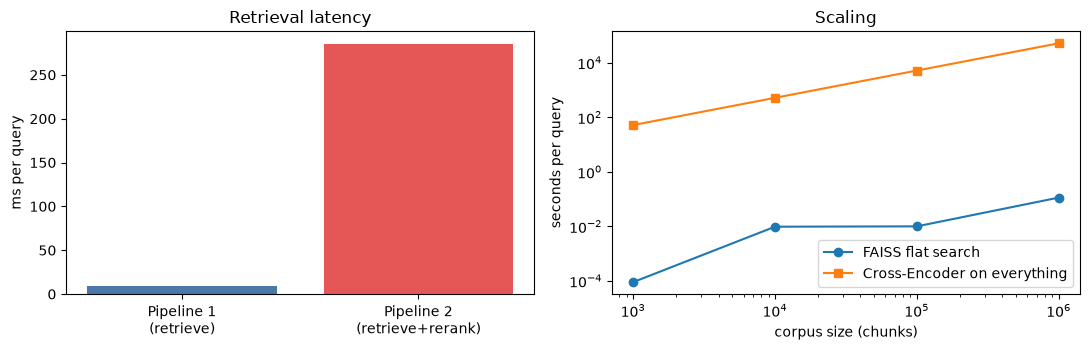

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(["Pipeline 1\n(retrieve)", "Pipeline 2\n(retrieve+rerank)"], [ms(t_base), ms(t_base) + ms(t_ce)], color=["#4c78a8", "#e45756"])
ax[0].set_ylabel("ms per query"); ax[0].set_title("Retrieval latency")
ax[1].loglog(scale_df.iloc[:, 0], scale_df.iloc[:, 1]/1000, "o-", label="FAISS flat search")
ax[1].loglog(scale_df.iloc[:, 0], scale_df.iloc[:, 2], "s-", label="Cross-Encoder on everything")
ax[1].set_xlabel("corpus size (chunks)"); ax[1].set_ylabel("seconds per query"); ax[1].legend(); ax[1].set_title("Scaling")
plt.tight_layout(); plt.savefig("results/latency.png", dpi=130); plt.show()

## 8. Save raw results
Everything above is written to `results/` so the report can cite exact numbers.

In [13]:
with open("results/query_results.json", "w") as f:
    json.dump(results, f, indent=1)
print("saved", len(results), "query records")

saved 10 query records
